# Notebook 2 — Auditoría de datos y muestra analítica (OE1 · bloque R1)

**Objetivo.** Responder *¿sobre qué población son válidos los resultados?* antes de estimar cualquier efecto.

Este notebook parte del archivo crudo del scraping (`data/data_wrangling_20250324_202229.csv`) y deja trazado,
paso a paso, cuántos avisos se pierden y por qué:

1. Inventario y diccionario de variables (cobertura y faltantes).
2. Exclusión por variables núcleo faltantes (misma regla del `notebook0`).
3. **Deduplicación** (nuevo): avisos re-publicados o publicados en dos distritos.
4. Reglas de depuración del `notebook1` (F1–F6), ahora con conteo por motivo, y un **filtro mínimo** alternativo para robustez.
5. Unidades de dependencia: `edificio_id` (mismas coordenadas) y `celda_1km` (bloque espacial), usadas después para el cross-fitting y los errores estándar agrupados.
6. Perfil territorial (cobertura por distrito) y mapa de la muestra (figura F2).

El resultado es `csv/data_causal_base.csv`: **sin textos ni direcciones** (privacidad) y con banderas para reconstruir cada variante de la muestra.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from causal_utils import *

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
ORIGEN = "notebook2_auditoria.ipynb"

raw = pd.read_csv("../data/data_wrangling_20250324_202229.csv")
N0 = len(raw)
print("Avisos en el archivo crudo:", N0, "| columnas:", raw.shape[1])

Avisos en el archivo crudo: 3739 | columnas: 13


## 1. Inventario y diccionario de variables

In [2]:
desc = {
 "precio": "Precio de oferta mensual (S/). Resultado Y = log(precio)",
 "banos": "Número de baños. Tratamiento T",
 "area": "Área (m2) declarada en el aviso",
 "dormitorios": "Número de dormitorios",
 "antiguedad": "Años de antigüedad del inmueble",
 "distrito": "Distrito de búsqueda del portal (13 distritos)",
 "latitud": "Latitud geocodificada desde la dirección",
 "longitud": "Longitud geocodificada desde la dirección",
 "precision": "Precisión de la geocodificación (ROOFTOP, APPROXIMATE, ...)",
 "type": "Tipo de lugar devuelto por el geocodificador",
 "fecha_publicacion": "Días desde la publicación del aviso",
 "descripcion": "Texto libre del aviso (solo para deduplicar; no se exporta)",
 "direccion": "Dirección (dato sensible; no se exporta)",
}
dicc = pd.DataFrame({"variable": raw.columns,
                     "tipo": [str(raw[c].dtype) for c in raw.columns],
                     "faltantes": [int(raw[c].isna().sum()) for c in raw.columns],
                     "% faltante": [100 * raw[c].isna().mean() for c in raw.columns],
                     "descripción": [desc.get(c, "") for c in raw.columns]})
guardar_tabla(dicc, "R1_diccionario", decimales=1, origen=ORIGEN)
dicc

,variable,tipo,faltantes,% faltante,descripción
0,longitud,float64,0,0.000000,Longitud geocodificada desde la dirección
1,descripcion,str,16,0.427922,Texto libre del aviso (solo para deduplicar; n...
2,area,float64,160,4.279219,Área (m2) declarada en el aviso
3,banos,float64,30,0.802354,Número de baños. Tratamiento T
4,precio,float64,62,1.658197,Precio de oferta mensual (S/). Resultado Y = l...
5,latitud,float64,0,0.000000,Latitud geocodificada desde la dirección
6,dormitorios,float64,44,1.176785,Número de dormitorios
7,fecha_publicacion,float64,5,0.133726,Días desde la publicación del aviso
8,distrito,str,2,0.053490,Distrito de búsqueda del portal (13 distritos)
9,antiguedad,float64,1149,30.730142,Años de antigüedad del inmueble


## 2. Variables núcleo faltantes

Se excluyen los avisos sin `dormitorios`, `banos`, `area`, `precio` o `distrito` (no se imputa el tratamiento, el resultado ni el área).
Los 5 avisos sin `fecha_publicacion` se completan con la mediana (11 días): es un control secundario y afecta al 0,1 % de la muestra.

In [3]:
log = [("Archivo crudo del scraping", N0, 0)]
d = raw.dropna(subset=["dormitorios", "banos", "area", "precio", "distrito"]).copy()
log.append(("Sin dormitorios/baños/área/precio/distrito", len(d), N0 - len(d)))
d["dormitorios"] = d["dormitorios"].astype(int); d["banos"] = d["banos"].astype(int)
d["dias_pub"] = d["fecha_publicacion"].fillna(d["fecha_publicacion"].median())
d["precioxm2"] = d["precio"] / d["area"]
d = d.reset_index(drop=True); d["id_aviso"] = np.arange(len(d))
print("Tras núcleo:", len(d))

# Comprobación: las reglas F1-F6 reproducen la muestra del notebook1 (3 276 avisos)
print("Reproducción notebook1 (sin deduplicar):", int(motivo_filtro_principal(d).isna().sum()))

Tras núcleo: 3516
Reproducción notebook1 (sin deduplicar): 3276


## 3. Deduplicación

El portal permite que un mismo departamento aparezca más de una vez. Se identificaron dos patrones:

* **D1 – re-publicación**: mismo texto normalizado **y** mismos área, dormitorios y baños, con precio a ±10 %.
  Incluye avisos idénticos capturados bajo dos distritos distintos (el scraping buscó por distrito y el aviso aparecía en ambos).
  Cuando el texto coincide pero los atributos no, se trata de una *plantilla* de la inmobiliaria para otra unidad y **no** se marca.
* **D2 – publicación cruzada**: mismas coordenadas (4 decimales ≈ 11 m), área, dormitorios, baños y precio, con texto distinto
  (el mismo inmueble publicado por otro corredor).

En cada grupo se conserva el aviso **más reciente** (menos días publicado). Los casos D2 son ambiguos (podrían ser dos unidades idénticas
del mismo edificio); por eso el notebook 3 repite la estimación **sin deduplicar**.

In [4]:
d["txt"] = d["descripcion"].map(normalizar_texto)
d["lat4"], d["lon4"] = d["latitud"].round(4), d["longitud"].round(4)
d = d.sort_values(["dias_pub", "id_aviso"]).reset_index(drop=True)   # el primero de cada grupo = más reciente

# D1: mismo texto + mismos atributos + precio a +-10% respecto del aviso conservado
d["grupo_d1"] = d.groupby(["txt", "area", "dormitorios", "banos"]).ngroup()
ref = d.groupby("grupo_d1")["precio"].transform("first")
es_d1 = d.duplicated("grupo_d1") & ((d["precio"] / ref - 1).abs() <= 0.10) & (d["txt"].str.len() > 0)

# D2: mismas coordenadas y atributos con texto distinto (entre los que no son D1)
resto = d[~es_d1]
es_d2 = pd.Series(False, index=d.index)
es_d2[resto.index] = resto.duplicated(["lat4", "lon4", "area", "dormitorios", "banos", "precio"])

d["es_duplicado"] = (es_d1 | es_d2).astype(int)
d["regla_dup"] = np.select([es_d1, es_d2], ["D1 re-publicación", "D2 publicación cruzada"], "")
dist_dup = es_d1 & (d["distrito"] != d.groupby("grupo_d1")["distrito"].transform("first"))
print("D1 re-publicaciones:", int(es_d1.sum()), "| de ellas en otro distrito:", int(dist_dup.sum()))
print("D2 publicaciones cruzadas:", int(es_d2.sum()))
print("Total marcados como duplicado:", int(d["es_duplicado"].sum()))
log.append(("Duplicados D1 (re-publicación)", len(d) - int(es_d1.sum()), int(es_d1.sum())))
log.append(("Duplicados D2 (publicación cruzada)", len(d) - int(d["es_duplicado"].sum()), int(es_d2.sum())))

D1 re-publicaciones: 166 | de ellas en otro distrito: 83
D2 publicaciones cruzadas: 77
Total marcados como duplicado: 243


### Geocodificación incoherente

Algunas direcciones se geocodificaron lejos del distrito del aviso (un caso de San Miguel cae a 141 km, cerca de Cañete).
Como un distrito de la muestra no supera unos 8 km de radio, se excluyen los avisos ubicados a **más de 8 km de la mediana de su distrito**.
Es una regla de calidad de medición: no usa el precio.

In [5]:
P = coords_km(d["latitud"], d["longitud"])
med = pd.DataFrame(P, columns=["x", "y"]).groupby(d["distrito"].values).transform("median").values
d["dist_mediana_km"] = np.hypot(P[:, 0] - med[:, 0], P[:, 1] - med[:, 1])
d["geo_incoherente"] = (d["dist_mediana_km"] > 8).astype(int)
k = int(((d["geo_incoherente"] == 1) & (d["es_duplicado"] == 0)).sum())
print("Avisos (no duplicados) con coordenada incoherente:", k)
print(d.loc[d["geo_incoherente"] == 1, "precision"].value_counts().to_dict())
log.append(("G1 geocodificación incoherente (>8 km del distrito)", log[-1][1] - k, k))

Avisos (no duplicados) con coordenada incoherente: 26
{'ROOFTOP': 13, 'GEOMETRIC_CENTER': 11, 'RANGE_INTERPOLATED': 3, 'APPROXIMATE': 1}


## 4. Reglas de depuración (F1–F6) y filtro mínimo

Las reglas F1–F6 son las del `notebook1`. Varias usan el precio o el precio/m² (selección basada en el resultado), por eso se define además un
**filtro mínimo predefinido** que solo elimina errores groseros (área 15–1 000 m², precio S/300–30 000, 1–6 dormitorios y baños) y se usa como
especificación alternativa en el notebook 3 (sin elegir entre ellas por significancia).

In [6]:
u = d[(d["es_duplicado"] == 0) & (d["geo_incoherente"] == 0)].copy()
motivo = motivo_filtro_principal(u)
n = len(u)
for m in sorted(motivo.dropna().unique()):
    k = int((motivo == m).sum()); n -= k
    log.append((m, n, k))
N_final = int(motivo.isna().sum())
excl = pd.DataFrame(log, columns=["paso", "N restante", "excluidos"])
excl["% del crudo"] = 100 * excl["N restante"] / N0
guardar_tabla(excl, "R1_exclusiones", decimales=1, origen=ORIGEN)
display(excl)

alt = pd.DataFrame({
  "variante de muestra": ["Principal (dedup + G1 + F1-F6)", "Sin deduplicar (G1 + F1-F6)", "Dedup + G1 + filtro mínimo",
                          "Principal sin geocodificación APPROXIMATE"],
  "N": [N_final, int(motivo_filtro_principal(d[d["geo_incoherente"] == 0]).isna().sum()), int(pasa_filtro_minimo(u).sum()),
        int((motivo.isna() & (u["precision"] != "APPROXIMATE")).sum())]})
guardar_tabla(alt, "R1_variantes_muestra", origen=ORIGEN)
alt

,paso,N restante,excluidos,% del crudo
0,Archivo crudo del scraping,3739,0,100.000000
1,Sin dormitorios/baños/área/precio/distrito,3516,223,94.035838
2,Duplicados D1 (re-publicación),3350,166,89.596149
3,Duplicados D2 (publicación cruzada),3273,77,87.536775
4,G1 geocodificación incoherente (>8 km del dist...,3247,26,86.841401
5,"F1 rangos (dorm>6, área>600, precio/m2 fuera d...",3117,130,83.364536
6,"F2 área incoherente (<=2 dorm, 1 baño, >=160 m2)",3116,1,83.337791
7,F4 precio < 600,3065,51,81.973790
8,F5 combinación dorm-baños rara (<=3 casos),3049,16,81.545868
9,F6 precio/m2 atípico en su distrito,3028,21,80.984220


,variante de muestra,N
0,Principal (dedup + G1 + F1-F6),3028
1,Sin deduplicar (G1 + F1-F6),3248
2,Dedup + G1 + filtro mínimo,3243
3,Principal sin geocodificación APPROXIMATE,2508


## 5. Unidades de dependencia espacial

* `edificio_id`: avisos con las mismas coordenadas redondeadas a 4 decimales (~11 m). Es la unidad que **no** debe repartirse entre folds
  (evita que el modelo “vea” el mismo edificio al entrenar y al evaluar) y el cluster principal para los errores estándar.
* `celda_1km`: bloque espacial de ~1 km × 1 km, usado como agrupamiento alternativo más grueso.

Las coordenadas con precisión `APPROXIMATE` son centroides (de calle o zona): agrupan muchos avisos en un solo punto. Tratarlos como un solo
cluster es conservador; además se reporta la estimación excluyéndolos.

In [7]:
d["edificio_id"] = d.groupby(["lat4", "lon4"]).ngroup()
d["celda_1km"] = (np.floor(d["latitud"] / 0.009).astype(int).astype(str) + "_" +
                  np.floor(d["longitud"] / 0.0092).astype(int).astype(str))
fin = u[motivo.isna()].copy()
fin["edificio_id"], fin["celda_1km"] = d.loc[fin.index, "edificio_id"], d.loc[fin.index, "celda_1km"]
tam = fin.groupby("edificio_id").size()
grp = pd.DataFrame({
  "agrupamiento": ["edificio_id", "celda_1km", "distrito"],
  "n grupos": [fin["edificio_id"].nunique(), fin["celda_1km"].nunique(), fin["distrito"].nunique()],
  "tamaño mediano": [fin.groupby(c).size().median() for c in ["edificio_id", "celda_1km", "distrito"]],
  "tamaño máximo": [fin.groupby(c).size().max() for c in ["edificio_id", "celda_1km", "distrito"]],
  "% avisos en grupos >1": [100 * (fin.groupby(c)[c].transform("size") > 1).mean() for c in ["edificio_id", "celda_1km", "distrito"]]})
guardar_tabla(grp, "R1_agrupamientos", decimales=1, origen=ORIGEN)
display(grp)
print("Edificios grandes (>20 avisos) por precisión:")
print(pd.crosstab(fin["edificio_id"].map(tam) > 20, fin["precision"]))

,agrupamiento,n grupos,tamaño mediano,tamaño máximo,% avisos en grupos >1
0,edificio_id,2178,1.0,68,37.186262
1,celda_1km,183,8.0,103,99.009247
2,distrito,13,218.0,460,100.000000


Edificios grandes (>20 avisos) por precisión:
precision    APPROXIMATE  GEOMETRIC_CENTER  RANGE_INTERPOLATED  ROOFTOP
edificio_id                                                            
False                 45               259                  22     2225
True                 475                 1                   0        1


## 6. Perfil territorial y faltantes de la muestra final

In [8]:
cob = (fin.groupby("distrito")
         .agg(N=("precio", "size"), precio_mediano=("precio", "median"), area_mediana=("area", "median"),
              banos_medio=("banos", "mean"), pct_rooftop=("precision", lambda x: 100 * (x == "ROOFTOP").mean()),
              pct_antig_faltante=("antiguedad", lambda x: 100 * x.isna().mean()))
         .reset_index())
cob.insert(1, "clase", cob["distrito"].map(CLASE))
cob.insert(3, "% muestra", 100 * cob["N"] / cob["N"].sum())
cob = cob.sort_values(["clase", "distrito"]).reset_index(drop=True)
cob = cob.rename(columns={"precio_mediano": "precio mediano", "area_mediana": "área mediana", "banos_medio": "baños medio",
                          "pct_rooftop": "% ROOFTOP", "pct_antig_faltante": "% antig. faltante"})
guardar_tabla(cob, "R1_cobertura_distrito", decimales=1, origen=ORIGEN)
display(cob)

falt = pd.DataFrame({"variable": ["antiguedad", "fecha_publicacion"],
                     "faltantes en muestra final": [int(fin["antiguedad"].isna().sum()), int(fin["fecha_publicacion"].isna().sum())],
                     "%": [100 * fin["antiguedad"].isna().mean(), 100 * fin["fecha_publicacion"].isna().mean()],
                     "tratamiento": ["0 + indicador antig_na (sin usar otras filas)", "mediana (11 días)"]})
guardar_tabla(falt, "R1_faltantes", decimales=1, origen=ORIGEN)
display(falt)
print("Distribución del tratamiento (baños):"); print(fin["banos"].value_counts().sort_index())

,distrito,clase,N,% muestra,precio mediano,área mediana,baños medio,% ROOFTOP,% antig. faltante
0,barranco,clase1,246,8.124174,2762.5,64.0,1.593496,97.154472,0.000000
1,lince,clase1,218,7.199472,2300.0,60.0,1.600917,63.761468,40.825688
2,miraflores,clase1,460,15.191546,3699.0,99.0,2.002174,92.826087,0.000000
3,san-isidro,clase1,267,8.817701,3515.0,100.0,1.910112,67.415730,29.588015
4,jesus-maria,clase2,175,5.779392,2400.0,72.0,1.811429,67.428571,36.000000
5,magdalena,clase2,130,4.293263,2570.0,80.0,2.007692,80.769231,19.230769
6,san-borja,clase2,265,8.751651,2800.0,98.0,1.981132,62.641509,39.622642
7,surco,clase2,242,7.992074,2700.0,90.0,2.107438,68.595041,23.553719
8,surquillo,clase2,205,6.770145,2250.0,70.0,1.770732,61.463415,36.585366
9,cercado,clase3,206,6.803170,2000.0,67.0,1.635922,57.766990,46.601942


,variable,faltantes en muestra final,%,tratamiento
0,antiguedad,758,25.033025,0 + indicador antig_na (sin usar otras filas)
1,fecha_publicacion,0,0.000000,mediana (11 días)


Distribución del tratamiento (baños):
banos
1    1065
2    1480
3     407
4      69
5       7
Name: count, dtype: int64


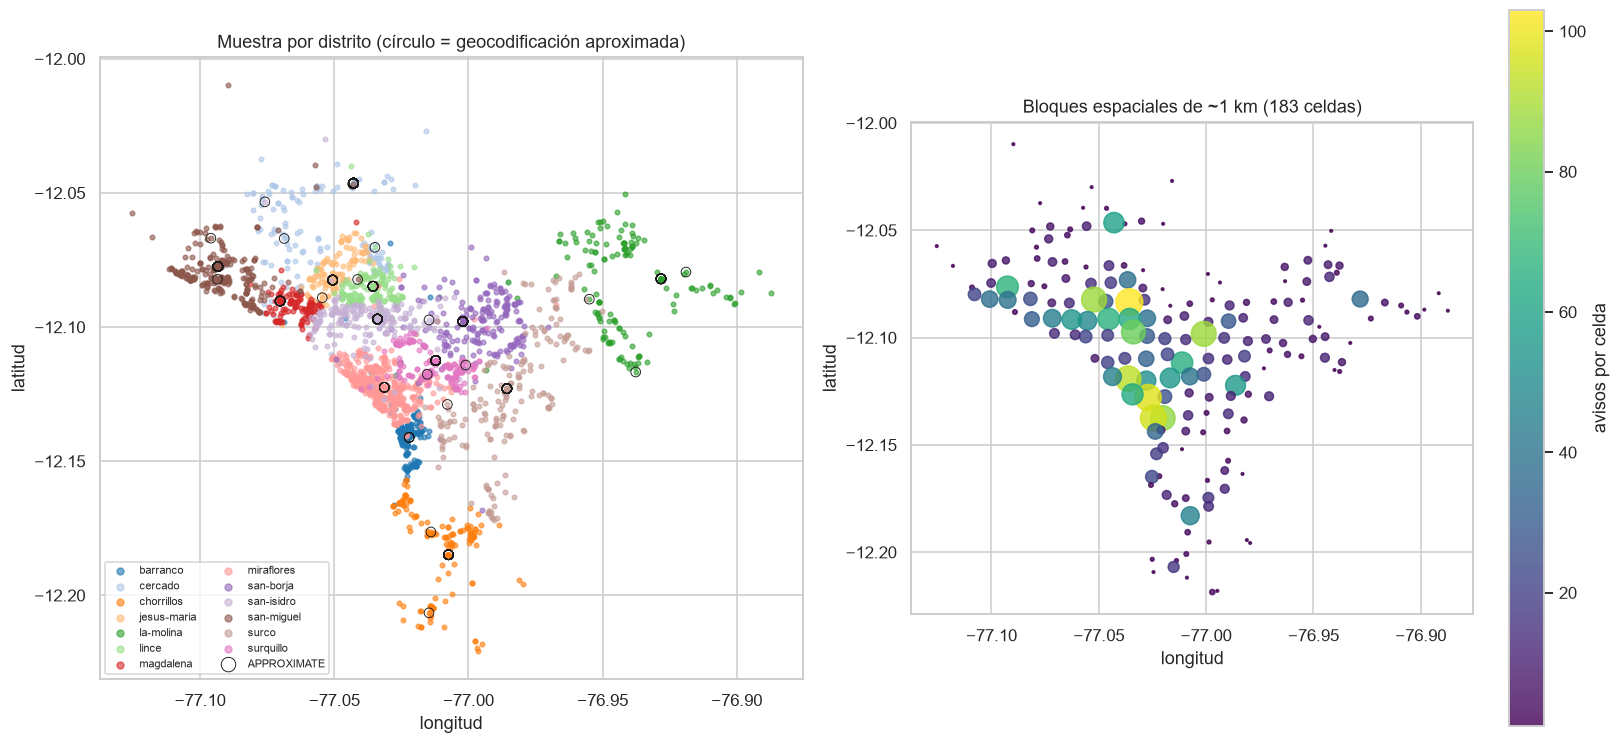

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
pal = dict(zip(sorted(fin["distrito"].unique()), sns.color_palette("tab20", fin["distrito"].nunique())))
for dist, g in fin.groupby("distrito"):
    ax[0].scatter(g["longitud"], g["latitud"], s=9, alpha=.6, color=pal[dist], label=dist)
ap = fin[fin["precision"] == "APPROXIMATE"]
ax[0].scatter(ap["longitud"], ap["latitud"], s=40, facecolors="none", edgecolors="k", lw=.6, label="APPROXIMATE")
ax[0].set_xlabel("longitud"); ax[0].set_ylabel("latitud"); ax[0].set_aspect("equal")
ax[0].legend(fontsize=7, markerscale=1.5, loc="lower left", ncol=2); ax[0].set_title("Muestra por distrito (círculo = geocodificación aproximada)")
cel = fin.groupby("celda_1km").agg(lat=("latitud", "mean"), lon=("longitud", "mean"), n=("precio", "size"))
sc = ax[1].scatter(cel["lon"], cel["lat"], s=cel["n"] * 3, c=cel["n"], cmap="viridis", alpha=.8)
plt.colorbar(sc, ax=ax[1], label="avisos por celda"); ax[1].set_aspect("equal")
ax[1].set_xlabel("longitud"); ax[1].set_ylabel("latitud"); ax[1].set_title(f"Bloques espaciales de ~1 km ({len(cel)} celdas)")
plt.tight_layout(); plt.savefig(FIG / "F2_territorio.png", bbox_inches="tight"); plt.show()

## 7. Exportar la base auditada

Se exportan todos los avisos con núcleo completo (incluidos los duplicados, marcados) para poder reconstruir cada variante con
`causal_utils.muestra(...)`. No se exportan `descripcion` ni `direccion`.

In [10]:
cols = ["id_aviso", "precio", "banos", "area", "dormitorios", "antiguedad", "distrito", "latitud", "longitud",
        "precision", "type", "fecha_publicacion", "dias_pub", "precioxm2", "es_duplicado", "regla_dup",
        "dist_mediana_km", "geo_incoherente", "edificio_id", "celda_1km"]
base = d.sort_values("id_aviso")[cols].reset_index(drop=True)
base.to_csv("../csv/data_causal_base.csv", index=False)
m = muestra(base)
print("Base exportada:", base.shape, "| muestra principal reconstruida:", len(m))

Base exportada: (3516, 20) | muestra principal reconstruida: 3028
